# Logistic Regression: Diagnosing Breast Tumours

**Family:** Supervised learning | **Level:** Beginner | **Dataset:** `breast_cancer` | **Runs on:** CPU, about 1 minute(s)

Model the probability of malignancy and learn how regularisation and thresholds change decisions.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How the sigmoid turns a linear score into a probability
- What log loss and maximum likelihood mean
- How the decision threshold changes precision and recall
- How regularisation strength C acts

**Prerequisites:**

- Linear regression notebook
- Probability basics

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Fine needle aspiration is a quick, low cost test. Cell nuclei in the sample are measured from digitised images.

**The problem.** Classify a tumour as malignant or benign from 30 nucleus measurements.

**Why it matters.** A missed malignancy costs far more than a false alarm, so the error trade-off must be explicit.

**Why machine learning.** Many measurements together separate the classes better than any single one.

**Why this algorithm.** Logistic regression gives calibrated style probabilities and readable coefficients, which clinicians prefer.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Multisurface method of pattern separation for medical diagnosis applied to breast cytology

- **Type:** application paper
- **Authors:** Wolberg, W. H. and Mangasarian, O. L.
- **Year and venue:** 1990, PNAS 87(23):9193-9196
- **DOI or URL:** https://doi.org/10.1073/pnas.87.23.9193
- **Verification:** Crossref 2026-11-17
- **Research objective:** Diagnose breast masses from fine needle aspirate features.
- **Methodology:** Piecewise linear separation of benign and malignant cases by linear programming.
- **Dataset:** Cytology samples collected at the University of Wisconsin hospitals.
- **Main findings:** Reports high diagnostic accuracy on the collected samples.
- **Limitations:** Single institution, small sample, early version of the dataset used here.

### The Elements of Statistical Learning (2nd ed.)

- **Type:** foundational paper
- **Authors:** Hastie, T., Tibshirani, R. and Friedman, J.
- **Year and venue:** 2009, Springer
- **DOI or URL:** https://doi.org/10.1007/978-0-387-84858-7
- **Verification:** not verified in build environment
- **Research objective:** Textbook on statistical learning.
- **Methodology:** Textbook.
- **Dataset:** Not applicable.
- **Main findings:** Reference text.
- **Limitations:** Textbook.

**Relationship to this notebook.** Wolberg and Mangasarian used earlier cytology features from the same research group. The 30 feature version used here was released later. We use a different model, so the paper is context, not a baseline to match. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Model.** $P(y=1\mid x) = \sigma(\beta_0 + x^\top\beta)$ with $\sigma(z) = \dfrac{1}{1+e^{-z}}$.

**Objective (regularised negative log likelihood).**

$$J(\beta) = -\sum_{i}\big[y_i \log p_i + (1-y_i)\log(1-p_i)\big] + \frac{1}{2C}\lVert\beta\rVert_2^2, \quad p_i = \sigma(\beta_0 + x_i^\top\beta)$$

**Gradient.** $\nabla J = A^\top (p - y) + \beta/C$. The objective is convex, so gradient methods reach the global optimum.

**Odds interpretation.** $e^{\beta_j}$ is the multiplicative change in odds for a one unit increase of feature $j$.

**Assumptions.** Log odds linear in features, independent rows, no perfect separation (or use regularisation).

**Limitations.** Linear decision boundary, needs scaling for regularisation, probabilities can be miscalibrated under strong penalty.

## 5. Dataset Introduction

**Breast Cancer Wisconsin (Diagnostic)**, UCI, licence CC BY 4.0, DOI 10.24432/C5DW2B. 569 rows, 30 numeric features (mean, standard error and worst value of ten nucleus properties computed from digitised fine needle aspirate images). Target `malignant` (1 malignant, 0 benign). No missing values. Limits: one institution, small sample.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "logistic_regression"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("breast_cancer")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: classification | target: malignant | shape: (569, 31)


,source
title,Breast Cancer Wisconsin (Diagnostic)
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/17/breast+...
license,CC BY 4.0
doi,10.24432/C5DW2B
rows,569
features,30
limits,"Single institution, small sample, features com..."


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. Many nucleus measures are strongly correlated (radius, perimeter, area).

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (569, 31)


,columns by dtype
float64,30
int64,1


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


Columns with missing values: 0


,missing,percent


Duplicate rows: 0


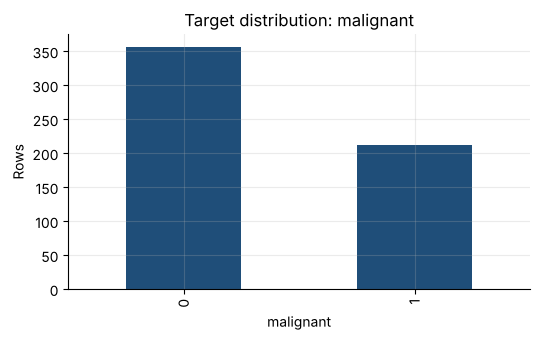

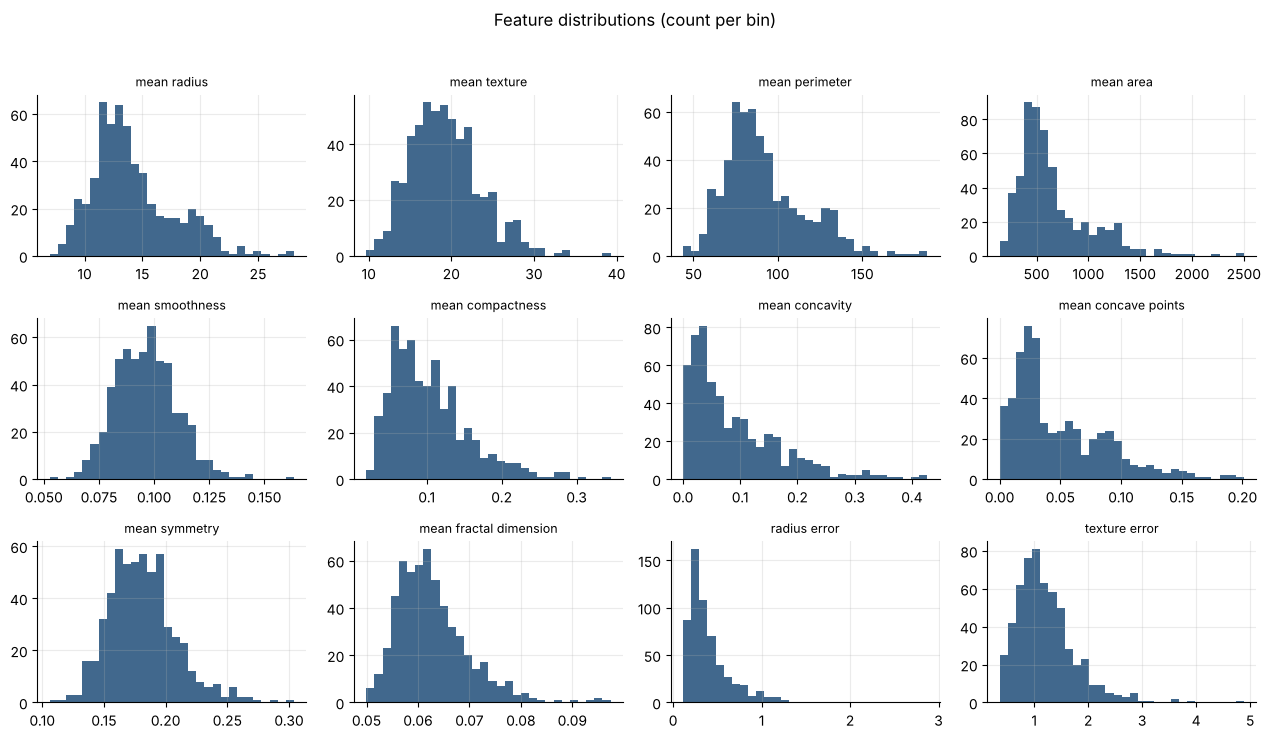

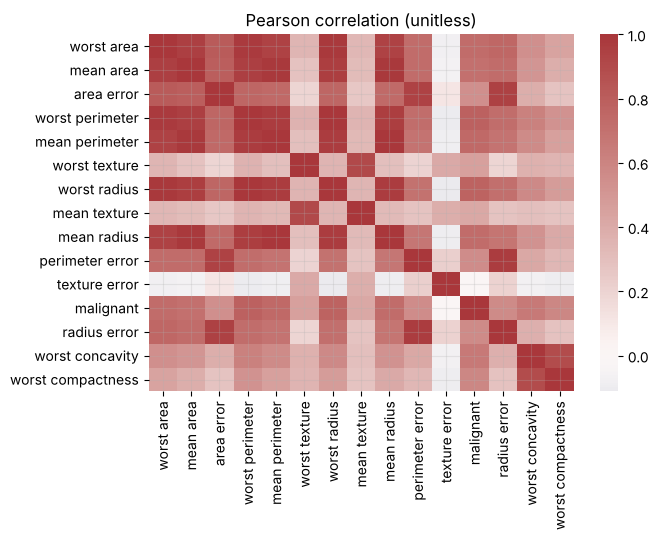

,feature,outliers,percent
0,area error,65,11.42
1,radius error,38,6.68
2,perimeter error,38,6.68
3,worst area,35,6.15
4,smoothness error,30,5.27
5,fractal dimension error,28,4.92
6,compactness error,28,4.92
7,symmetry error,27,4.75


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.


In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=True, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 341 114 114


,train,validation,test
malignant,,,
0,0.628,0.623,0.632
1,0.372,0.377,0.368


transformed train shape: (341, 30)


## 8. Algorithm Implementation

### 8.1 Concept

The model draws a hyperplane in feature space. The distance to the plane, passed through the sigmoid, is the predicted probability of malignancy.

### 8.2 Python implementation from scratch

We implement gradient descent on the log loss with NumPy and compare with scikit-learn.

validation accuracy scratch: 0.9737 | sklearn: 0.9561 | prediction agreement: 0.9825


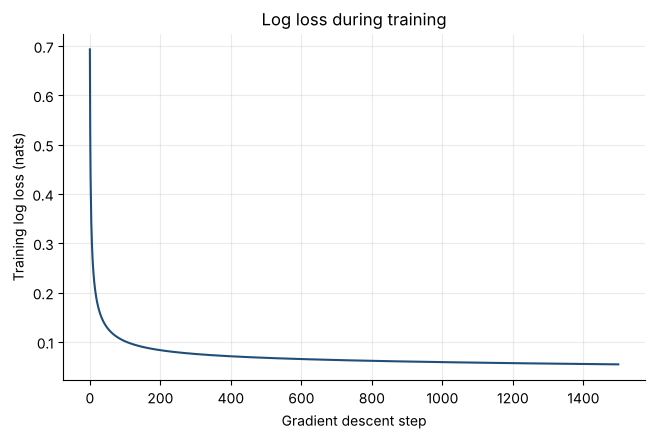

In [6]:
ytr = y_train.values.astype(float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class LogisticScratch:
    def fit(self, X, y, lr=0.1, steps=1500, l2=0.0):
        A = np.c_[np.ones(len(X)), X]
        w = np.zeros(A.shape[1])
        self.loss = []
        for _ in range(steps):
            p = sigmoid(A @ w)
            w -= lr * (A.T @ (p - y) / len(y) + l2 * np.r_[0, w[1:]])
            self.loss.append(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)))
        self.w = w
        return self

    def predict_proba(self, X):
        return sigmoid(np.c_[np.ones(len(X)), X] @ self.w)

mine = LogisticScratch().fit(Xtr, ytr)
ref = LogisticRegression(C=1e4, max_iter=5000).fit(Xtr, ytr)
agree = np.mean((mine.predict_proba(Xva) > 0.5) == ref.predict(Xva))
print("validation accuracy scratch:", round(float(np.mean((mine.predict_proba(Xva) > 0.5) == y_val.values)), 4),
      "| sklearn:", round(float(ref.score(Xva, y_val)), 4), "| prediction agreement:", round(float(agree), 4))
plt.plot(mine.loss); plt.xlabel("Gradient descent step"); plt.ylabel("Training log loss (nats)")
plt.title("Log loss during training"); plt.show()

### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `C` | Inverse regularisation strength. Smaller C means a stronger penalty. |
| `l1_ratio` | 0 for L2, 1 for L1 (with the `saga` solver). |
| `class_weight` | Reweight classes for imbalance. |
| `max_iter` | Solver iterations. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "F1"
LOWER_IS_BETTER = False
SCORING = "f1"
SWEEP_PARAM = "model__C"
SWEEP_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]

def build_pipeline():
    return make_model_pipeline(X_train, LogisticRegression(max_iter=5000), scale=True, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

LogisticRegression(max_iter=5000)


,F1,Accuracy,F1,ROC_AUC,PR_AUC
model__C,,,,,
0.001,0.8571,0.9035,0.8571,0.9797,0.9715
0.010,0.9512,0.9649,0.9512,0.9905,0.9878
0.100,0.9762,0.9825,0.9762,0.9951,0.9932
1.000,0.9655,0.9737,0.9655,0.9957,0.9946
10.000,0.9545,0.9649,0.9545,0.9957,0.9946
100.000,0.9438,0.9561,0.9438,0.9961,0.9949


best model__C on validation: 0.1
refit on train plus validation rows


## 10. Evaluation

Classification metrics: accuracy, precision, recall, F1, ROC-AUC and PR-AUC, plus the confusion matrix. With imbalanced classes accuracy alone misleads, so the model is chosen on F1 or PR-AUC as stated in the training cell.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "LogisticRegression": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="LogisticRegression", dataset="breast_cancer",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
baseline,0.6316,0.0,0.0000,0.0000,0.5000,0.3684
LogisticRegression,0.9825,1.0,0.9524,0.9756,0.9977,0.9966


5-fold CV f1: mean 0.9533, std 0.0309


saved logistic_regression.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

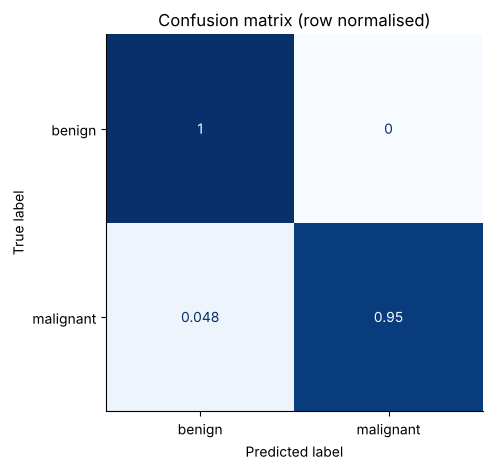

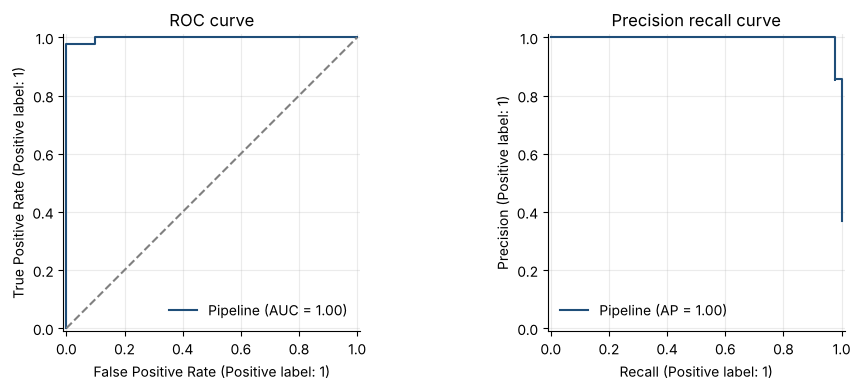

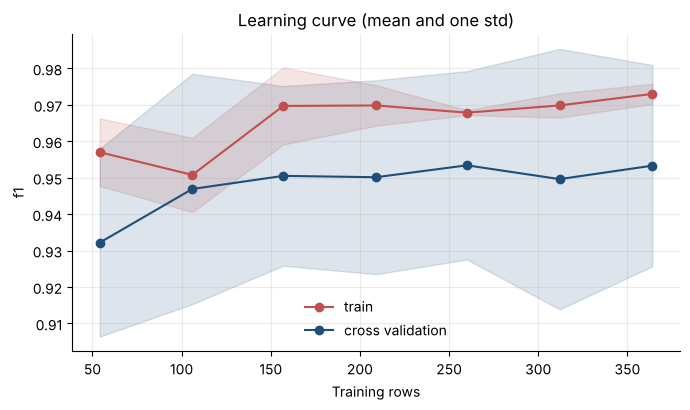

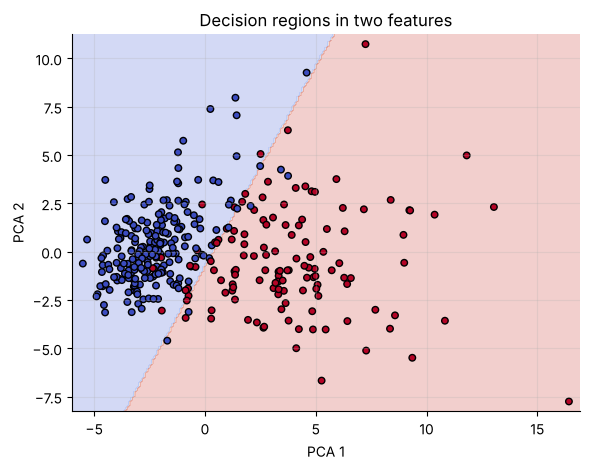

In [9]:
pred = final_model.predict(X_test)
labels = bundle.target_names or None
fig = viz.plot_confusion(y_test, pred, labels=labels)
save_figure(fig, NOTEBOOK_ID, "confusion"); plt.show()
if y_test.nunique() == 2:
    fig = viz.plot_roc_pr(final_model, X_test, y_test)
    save_figure(fig, NOTEBOOK_ID, "roc_pr"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()
# decision regions in two PCA axes
pca_view = PCA(n_components=2, random_state=SEED).fit(Xtr)
model_for_plot = clone(final_model.named_steps["model"])
fig = viz.plot_decision_boundary(lambda: clone(model_for_plot), pca_view.transform(Xtr), y_train.values,
                                 names=["PCA 1", "PCA 2"])
save_figure(fig, NOTEBOOK_ID, "decision_regions"); plt.show()

## 12. Interpretation

Permutation importance shows which inputs the model relies on. The confusion matrix shows which classes are mixed up, and the list of misclassified rows is the starting point for error analysis. A model is only as good as the cases it fails on.

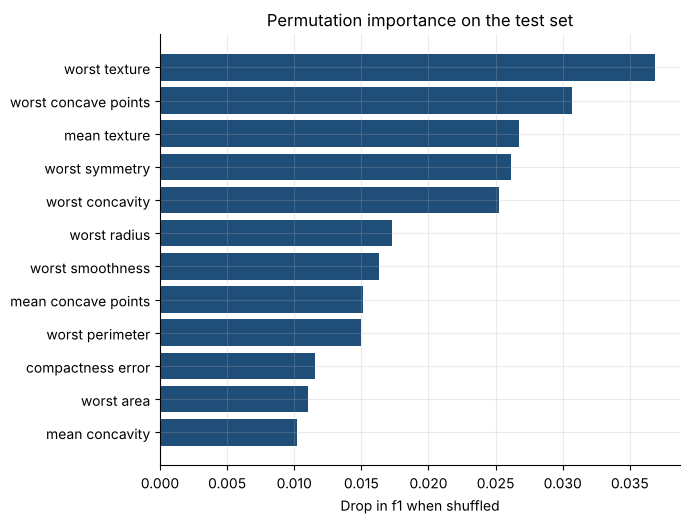

Top features: worst texture, worst concave points, mean texture, worst symmetry, worst concavity
Misclassified test rows: 2 of 114

Test F1: 0.9756 | baseline F1: 0.0000
Cross validation spread (std): 0.0309. A test gap larger than this spread is meaningful.


In [10]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Decision threshold

Move the probability threshold and watch precision and recall. We use cross validated probabilities on the training plus validation rows, never the test set.

In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score
proba = cross_val_predict(final_model, X_trainval, y_trainval, cv=5, method="predict_proba")[:, 1]
rows = [{"threshold": t, "precision": precision_score(y_trainval, proba >= t), "recall": recall_score(y_trainval, proba >= t)} for t in [0.1, 0.2, 0.3, 0.5, 0.7, 0.9]]
display(pd.DataFrame(rows).set_index("threshold").round(3))

,precision,recall
threshold,,
0.1,0.754,0.994
0.2,0.878,0.976
0.3,0.932,0.965
0.5,0.994,0.918
0.7,1.000,0.876
0.9,1.000,0.753


### Experiment 2: L1 versus L2 penalty

L1 sets coefficients to zero. Count the zeros at the same C.

In [12]:
for name, kw in [("L2", dict(l1_ratio=0.0)), ("L1", dict(l1_ratio=1.0))]:
    m = LogisticRegression(C=0.1, solver="saga", max_iter=5000, **kw).fit(Xtr, y_train)
    print(f"{name}: zero coefficients {(m.coef_ == 0).sum()} of {m.coef_.size}, validation accuracy {m.score(Xva, y_val):.3f}")

L2: zero coefficients 0 of 30, validation accuracy 0.982


L1: zero coefficients 25 of 30, validation accuracy 0.974


### Experiment 3: Reliability of the probabilities

A calibration curve compares predicted probability with the observed share of malignant cases.

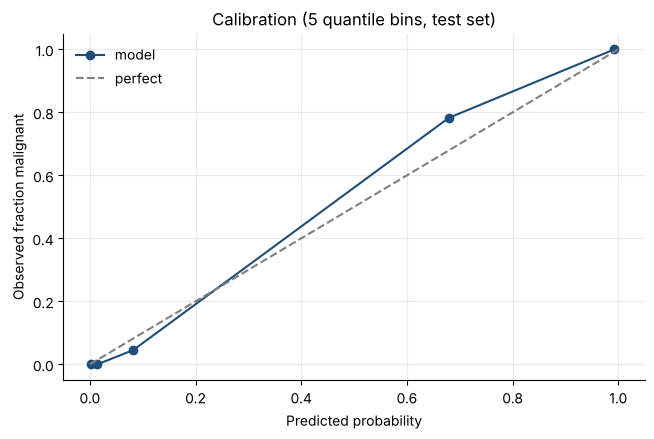

In [13]:
from sklearn.calibration import calibration_curve
prob = final_model.predict_proba(X_test)[:, 1]
frac, mean_pred = calibration_curve(y_test, prob, n_bins=5, strategy="quantile")
plt.plot(mean_pred, frac, marker="o", label="model"); plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect")
plt.xlabel("Predicted probability"); plt.ylabel("Observed fraction malignant"); plt.legend(); plt.title("Calibration (5 quantile bins, test set)"); plt.show()

### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Change the metric used for model choice and see whether the chosen value changes.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Wolberg and Mangasarian reported strong separation of benign and malignant samples with earlier features. Our model reaches a similar qualitative result on the later 30 feature release, but with a different model and split, so the numbers are not comparable.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Calibrate probabilities, choose the threshold from the cost of errors, and use repeated stratified cross validation because the test set is small.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Logistic regression is a linear model of log odds.
- Regularisation strength C is tuned on validation data.
- The threshold is a decision, not a model property.

**Use cases.** Medical screening scores, credit scoring, first baseline for any binary problem.

**Limitations.** Linear boundary and sensitivity to scaling.

**Recommended next notebook.** K-Nearest Neighbors.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.